# Lab 3: Clustering Analysis Using K-Means and K-Medoids Algorithms

**Name:** Amit Yadav  
**Course:** Advanced Big Data and Data Mining  
**Lab:** Lab 3 – Clustering Analysis Using K-Means and K-Medoids Algorithms

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_wine
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, adjusted_rand_score

In [2]:
wine = load_wine()

X = wine.data
y = wine.target

df = pd.DataFrame(X, columns=wine.feature_names)

print("Dataset Shape:", df.shape)
print("\nFeature Names:")
print(wine.feature_names)

print("\nFirst Five Rows:")
display(df.head())

Dataset Shape: (178, 13)

Feature Names:
['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']

First Five Rows:


,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0


In [3]:
class_distribution = pd.Series(y).value_counts().sort_index()

print("Class Distribution:")
print(class_distribution)

Class Distribution:
0    59
1    71
2    48
Name: count, dtype: int64


In [4]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print("Standardized data shape:", X_scaled.shape)

print("\nMean of standardized features:")
print(np.round(X_scaled.mean(axis=0), 2))

print("\nStandard deviation of standardized features:")
print(np.round(X_scaled.std(axis=0), 2))

Standardized data shape: (178, 13)

Mean of standardized features:
[ 0.  0. -0. -0. -0. -0.  0. -0. -0. -0.  0.  0. -0.]

Standard deviation of standardized features:
[1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]


## K-Means Clustering

K-Means clustering is applied with k = 3 because the Wine dataset contains three known classes. The Silhouette Score measures how well separated the clusters are, while the Adjusted Rand Index compares the predicted clusters with the actual class labels.

In [5]:
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)

kmeans_labels = kmeans.fit_predict(X_scaled)

kmeans_silhouette = silhouette_score(X_scaled, kmeans_labels)
kmeans_ari = adjusted_rand_score(y, kmeans_labels)

print("K-Means Silhouette Score:", round(kmeans_silhouette, 4))
print("K-Means Adjusted Rand Index:", round(kmeans_ari, 4))

K-Means Silhouette Score: 0.2849
K-Means Adjusted Rand Index: 0.8975


## K-Medoids Clustering

K-Medoids clustering is applied with k = 3. Unlike K-Means, K-Medoids uses actual observations from the dataset as cluster centers. The Silhouette Score and Adjusted Rand Index are used to evaluate its clustering performance.

In [6]:
from sklearn.metrics import pairwise_distances

def k_medoids(X, k=3, max_iter=100, random_state=42):
    rng = np.random.default_rng(random_state)
    medoid_indices = rng.choice(len(X), size=k, replace=False)

    for _ in range(max_iter):
        distances = pairwise_distances(X, X[medoid_indices])
        labels = np.argmin(distances, axis=1)

        new_medoid_indices = []

        for cluster_id in range(k):
            cluster_indices = np.where(labels == cluster_id)[0]

            if len(cluster_indices) == 0:
                new_medoid_indices.append(medoid_indices[cluster_id])
                continue

            cluster_distances = pairwise_distances(
                X[cluster_indices],
                X[cluster_indices]
            )

            total_distances = cluster_distances.sum(axis=1)
            best_index = cluster_indices[np.argmin(total_distances)]
            new_medoid_indices.append(best_index)

        new_medoid_indices = np.array(new_medoid_indices)

        if np.array_equal(medoid_indices, new_medoid_indices):
            break

        medoid_indices = new_medoid_indices

    distances = pairwise_distances(X, X[medoid_indices])
    labels = np.argmin(distances, axis=1)

    return labels, medoid_indices

kmedoids_labels, kmedoid_indices = k_medoids(
    X_scaled,
    k=3,
    random_state=42
)

kmedoids_silhouette = silhouette_score(X_scaled, kmedoids_labels)
kmedoids_ari = adjusted_rand_score(y, kmedoids_labels)

print("K-Medoids Silhouette Score:", round(kmedoids_silhouette, 4))
print("K-Medoids Adjusted Rand Index:", round(kmedoids_ari, 4))

K-Medoids Silhouette Score: 0.2676
K-Medoids Adjusted Rand Index: 0.7411


In [7]:
results = pd.DataFrame({
    "Algorithm": ["K-Means", "K-Medoids"],
    "Silhouette Score": [
        kmeans_silhouette,
        kmedoids_silhouette
    ],
    "Adjusted Rand Index": [
        kmeans_ari,
        kmedoids_ari
    ]
})

display(results.round(4))

,Algorithm,Silhouette Score,Adjusted Rand Index
0,K-Means,0.2849,0.8975
1,K-Medoids,0.2676,0.7411


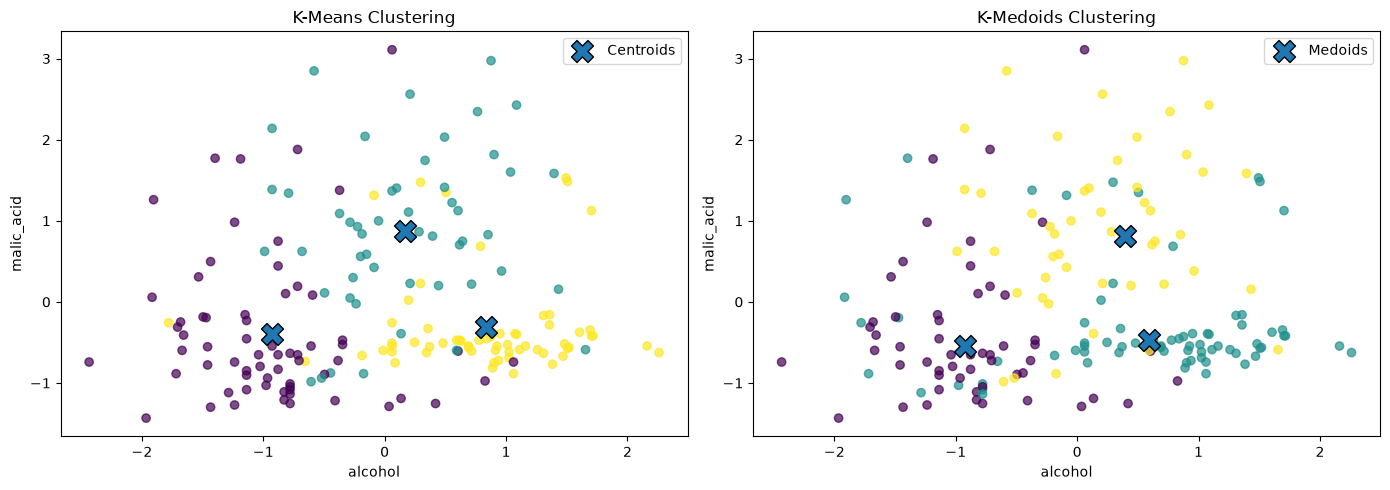

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# K-Means
axes[0].scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=kmeans_labels,
    cmap="viridis",
    alpha=0.7
)

axes[0].scatter(
    kmeans.cluster_centers_[:, 0],
    kmeans.cluster_centers_[:, 1],
    marker="X",
    s=250,
    edgecolor="black",
    label="Centroids"
)

axes[0].set_title("K-Means Clustering")
axes[0].set_xlabel(wine.feature_names[0])
axes[0].set_ylabel(wine.feature_names[1])
axes[0].legend()

# K-Medoids
medoid_points = X_scaled[kmedoid_indices]

axes[1].scatter(
    X_scaled[:, 0],
    X_scaled[:, 1],
    c=kmedoids_labels,
    cmap="viridis",
    alpha=0.7
)

axes[1].scatter(
    medoid_points[:, 0],
    medoid_points[:, 1],
    marker="X",
    s=250,
    edgecolor="black",
    label="Medoids"
)

axes[1].set_title("K-Medoids Clustering")
axes[1].set_xlabel(wine.feature_names[0])
axes[1].set_ylabel(wine.feature_names[1])
axes[1].legend()

plt.tight_layout()
plt.show()

## Results and Comparison

The clustering results show that K-Means performed better than K-Medoids on the standardized Wine dataset. K-Means achieved a Silhouette Score of 0.2849 and an Adjusted Rand Index of 0.8975, while K-Medoids achieved a Silhouette Score of 0.2676 and an Adjusted Rand Index of 0.7411. Since K-Means produced the higher value for both evaluation metrics, its clusters were better defined and more closely matched the actual Wine classes.

The scatter plots show that both algorithms identified three general groups, but their cluster centers were positioned differently. K-Means uses calculated centroids, so its centers are based on the average position of points within each cluster. K-Medoids uses actual observations as cluster representatives, which changes the cluster boundaries and the assignment of some observations.

K-Means may be preferable when the dataset is relatively clean and computational efficiency is important. K-Medoids may be preferable when the dataset contains unusual observations or outliers because medoids are actual data points and are less influenced by extreme values than arithmetic means.

Overall, K-Means produced the stronger clustering performance for this Wine dataset based on both the Silhouette Score and the Adjusted Rand Index.